In [1]:
import os, gc, json, math, random, time, platform, warnings, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from IPython.display import display

SEED = 651
HISTORY, HORIZON = 8, 4
N_EXPECTED = 716
HIDDEN = 24           
EMBED_DIM = 12
BATCH_SIZE = 64       
MAX_EPOCHS = 25
PATIENCE = 6
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 0       
TRAIN_STRIDE = 1      
DEV_FAST_RUN = False

ROOT = Path('/kaggle/input') if Path('/kaggle/input').exists() else Path('/mnt/data')
OUT = Path('/kaggle/working/pa3_results') if Path('/kaggle/working').exists() else Path('/mnt/data/pa3_results')
OUT.mkdir(parents=True, exist_ok=True)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
print('Device:', DEVICE, '| torch:', torch.__version__)
if torch.cuda.is_available(): print('GPU:', torch.cuda.get_device_name(0))
print('Output:', OUT)

Device: cuda | torch: 2.11.0+cu130
GPU: Tesla T4
Output: /kaggle/working/pa3_results


In [2]:
all_paths = sorted(p for p in ROOT.rglob('*') if p.is_file() and p.suffix.lower() in ('.h5','.hdf5','.csv','.npy','.npz'))
print('Found', len(all_paths), 'dataset-like files:')
for p in all_paths[:75]: print(' ', str(p), f'({p.stat().st_size/1e6:.1f} MB)')

def find_named(names):
    for name in names:
        candidates = [p for p in all_paths if p.name.lower() == name.lower()]
        if candidates: return sorted(candidates, key=lambda p: (len(str(p)), str(p)))[0]
    return None

meta_path = find_named(['sd_meta.csv','ca_meta.csv','metadata.csv'])
adj_path = find_named(['sd_rn_adj.npy','ca_rn_adj.npy','adj.npy'])
assert meta_path is not None, 'Attach the official LargeST dataset: metadata CSV not found.'
assert adj_path is not None, 'Attach the official LargeST dataset: adjacency .npy not found.'
print('Metadata:', meta_path)
print('Adjacency:', adj_path)

Found 7 dataset-like files:
  /kaggle/input/datasets/liuxu77/largest/ca_his_raw_2017.h5 (7233.3 MB)
  /kaggle/input/datasets/liuxu77/largest/ca_his_raw_2018.h5 (7233.3 MB)
  /kaggle/input/datasets/liuxu77/largest/ca_his_raw_2019.h5 (7233.3 MB)
  /kaggle/input/datasets/liuxu77/largest/ca_his_raw_2020.h5 (7253.1 MB)
  /kaggle/input/datasets/liuxu77/largest/ca_his_raw_2021.h5 (7233.3 MB)
  /kaggle/input/datasets/liuxu77/largest/ca_meta.csv (0.6 MB)
  /kaggle/input/datasets/liuxu77/largest/ca_rn_adj.npy (591.7 MB)
Metadata: /kaggle/input/datasets/liuxu77/largest/ca_meta.csv
Adjacency: /kaggle/input/datasets/liuxu77/largest/ca_rn_adj.npy


In [3]:
meta_all = pd.read_csv(meta_path)
meta_all.columns = [str(c).strip() for c in meta_all.columns]
print('Metadata columns:', list(meta_all.columns))
if 'District' in meta_all.columns:
    meta = meta_all.loc[pd.to_numeric(meta_all['District'], errors='coerce').eq(11)].copy()
elif 'district' in meta_all.columns:
    meta = meta_all.loc[pd.to_numeric(meta_all['district'], errors='coerce').eq(11)].copy()
else:
    assert len(meta_all) == N_EXPECTED, 'Cannot identify SD metadata: expected District or 716 SD rows.'
    meta = meta_all.copy()
meta = meta.reset_index(drop=True)
assert len(meta) == N_EXPECTED, f'SD selection gave {len(meta)} sensors, expected 716'
col_id = 'ID' if 'ID' in meta else ('id' if 'id' in meta else None)
assert col_id is not None, 'Metadata missing sensor ID column.'
sensor_ids = meta[col_id].astype(str).str.replace(r'\.0$', '', regex=True).tolist()
assert len(sensor_ids) == len(set(sensor_ids)), 'Sensor IDs must be unique.'

A_full = np.load(adj_path, allow_pickle=False)
assert A_full.ndim == 2 and A_full.shape[0] == A_full.shape[1], 'Expected square adjacency.'
if A_full.shape[0] == N_EXPECTED:
    A = A_full.copy()
else:
    assert 'ID2' in meta.columns, 'CA matrix needs ID2 column for correct indexing.'
    positions = meta['ID2'].astype(int).to_numpy()
    assert np.all((positions >= 0) & (positions < A_full.shape[0]))
    A = A_full[np.ix_(positions, positions)].copy()
A = A.astype(np.float32)
assert A.shape == (N_EXPECTED, N_EXPECTED)
assert np.isfinite(A).all(), 'Graph contains NaN/Inf; inspect before normalizing.'
np.fill_diagonal(A, 0.) 
print('SD selected:',len(sensor_ids),'sensors. Adjacency shape:',A.shape)
print('Adjacency nonzero range:', (float(A[A!=0].min()),float(A[A!=0].max())) if np.any(A!=0) else 'none')
del A_full; gc.collect()

Metadata columns: ['ID', 'Lat', 'Lng', 'District', 'County', 'Fwy', 'Lanes', 'Type', 'Direction', 'ID2']
SD selected: 716 sensors. Adjacency shape: (716, 716)
Adjacency nonzero range: (0.01000183541327715, 0.9999998807907104)


202

In [4]:
def locate_year(year):
    candidates = [f'sd_his_{year}.h5', f'ca_his_{year}.h5', f'ca_his_raw_{year}.h5',
                  f'data_{year}.h5', f'{year}.h5']
    exact = find_named(candidates)
    if exact is not None: return exact
    matches = [p for p in all_paths if p.suffix in ('.h5','.hdf5') and str(year) in p.name]
    if len(matches) == 1: return matches[0]
    raise FileNotFoundError(f'No unique HDF for {year}. Found: {[str(x) for x in matches]}')

def read_year(year):
    path = locate_year(year)
    print(f'Reading {year}: {path.name} ({path.stat().st_size/1e9:.2f} GB on disk)')
    with pd.HDFStore(path, mode='r') as store:
        keys = store.keys()
        print('  HDF keys:', keys)
        assert len(keys), f'No HDF keys: {path}'
        key = '/t' if '/t' in keys else ('/readings' if '/readings' in keys else keys[0])
        storer = store.get_storer(key)
        if getattr(storer, 'is_table', False):
            try: frame = store.select(key, columns=sensor_ids)
            except (KeyError, TypeError, ValueError): frame = store.get(key)
        else:
            frame = store.get(key)
    if not isinstance(frame, pd.DataFrame):
        raise TypeError('Expected pandas DataFrame HDF; examine file format and preprocessing.')
    frame.columns = frame.columns.map(lambda s: str(s).removesuffix('.0'))
    missing_cols = sorted(set(sensor_ids) - set(frame.columns))
    if missing_cols:
        if frame.shape[1] == N_EXPECTED and path.name.startswith('sd_'):
            warnings.warn('SD time series lacks matching ID labels: assuming metadata row order; verify manually.')
            frame.columns = sensor_ids
        else:
            raise ValueError(f'Missing {len(missing_cols)} SD sensor IDs in {path.name}; first: {missing_cols[:5]}')
    frame = frame.loc[:,sensor_ids].copy()
    del storer
    frame.index = pd.to_datetime(frame.index, errors='raise')
    assert isinstance(frame.index, pd.DatetimeIndex)
    frame = frame.loc[frame.index.year == year]
    assert len(frame)>0, f'No timestamps from {year} in file'
    assert not frame.index.has_duplicates, 'Duplicate 5-minute timestamps; resolve before resampling.'
    frame = frame.sort_index()
    frame = frame.apply(pd.to_numeric, errors='coerce').replace([np.inf,-np.inf],np.nan)
    frame[frame < 0] = np.nan  
    frame = frame.resample('15min').sum(min_count=1)
    expected = pd.date_range(f'{year}-01-01',f'{year}-12-31 23:45',freq='15min')
    frame = frame.reindex(expected)
    print('  15-min shape:',frame.shape,'missing %:',round(frame.isna().to_numpy().mean()*100,3))
    return frame.astype(np.float32)

frame20 = read_year(2020)
frame21 = read_year(2021)
assert frame20.shape == (366*96, N_EXPECTED)
assert frame21.shape == (365*96, N_EXPECTED)

Reading 2020: ca_his_raw_2020.h5 (7.25 GB on disk)
  HDF keys: ['/t']
  15-min shape: (35136, 716) missing %: 4.093
Reading 2021: ca_his_raw_2021.h5 (7.23 GB on disk)
  HDF keys: ['/t']
  15-min shape: (35040, 716) missing %: 6.028


In [5]:
train_df = frame20
val_df = frame21.loc['2021-01-01':'2021-03-31 23:45']
test_df = frame21.loc['2021-04-01':'2021-12-31 23:45']
assert train_df.index.max() < val_df.index.min() < test_df.index.min()
assert len(train_df)==366*96 and len(val_df)==90*96 and len(test_df)==275*96

nan_rates = {name:float(df.isna().to_numpy().mean()) for name,df in [('train',train_df),('validation',val_df),('test',test_df)]}
observed_train = train_df.to_numpy(dtype=np.float32)
global_mean = float(np.nanmean(observed_train)); global_std = float(np.nanstd(observed_train))
assert np.isfinite(global_mean) and np.isfinite(global_std) and global_std>0
with warnings.catch_warnings():
    warnings.simplefilter('ignore', category=RuntimeWarning)
    sensor_fill = np.nanmean(observed_train, axis=0)
sensor_fill = np.where(np.isfinite(sensor_fill),sensor_fill,global_mean).astype('float32')
print('Missing rate:', {k:round(v*100,3) for k,v in nan_rates.items()})
print('TRAIN-ONLY global mean/std:',global_mean,global_std)

def prep_split(df):
    raw = df.to_numpy(dtype='float32')
    mask = np.isfinite(raw)
    filled = np.where(mask,raw,sensor_fill[None,:]).astype('float32')
    return ((filled-global_mean)/global_std).astype('float32'), mask.astype(bool)

splits = {'train':prep_split(train_df), 'validation':prep_split(val_df), 'test':prep_split(test_df)}
np.save(OUT/'sensor_ids.npy', np.array(sensor_ids))
np.save(OUT/'sd_adjacency_raw.npy', A)
print('Train / validation / test rows:',*[len(x) for x in (train_df,val_df,test_df)])

Missing rate: {'train': 4.093, 'validation': 6.073, 'test': 6.013}
TRAIN-ONLY global mean/std: 607.2271118164062 483.39544677734375
Train / validation / test rows: 35136 8640 26400


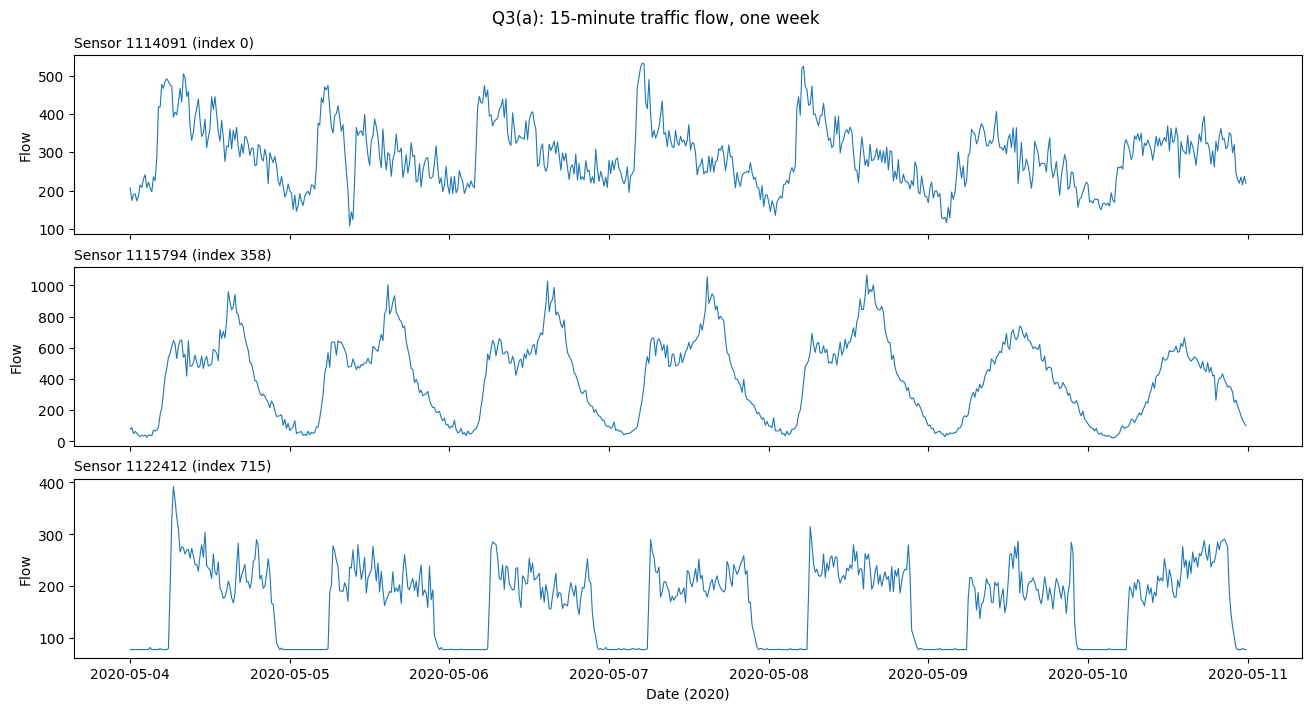

In [6]:
chosen = [0, N_EXPECTED//2, N_EXPECTED-1]
week = train_df.loc['2020-05-04':'2020-05-10 23:45']
fig,axes=plt.subplots(3,1,figsize=(13,7),sharex=True,constrained_layout=True)
for j,ax in zip(chosen,axes):
    ax.plot(week.index,week.iloc[:,j].values, lw=.8)
    ax.set_ylabel('Flow'); ax.set_title(f'Sensor {sensor_ids[j]} (index {j})',loc='left',fontsize=10)
axes[-1].set_xlabel('Date (2020)'); fig.suptitle('Q3(a): 15-minute traffic flow, one week')
fig.savefig(OUT/'q3_week_3_sensors.png',dpi=160); plt.show()

Nodes: 716 Directed nonzero edges (no loops): 17319
Weighted symmetric: False Unweighted topology symmetric: False
Out-degree min/mean/median/max: 0 24.18854748603352 20.0 70


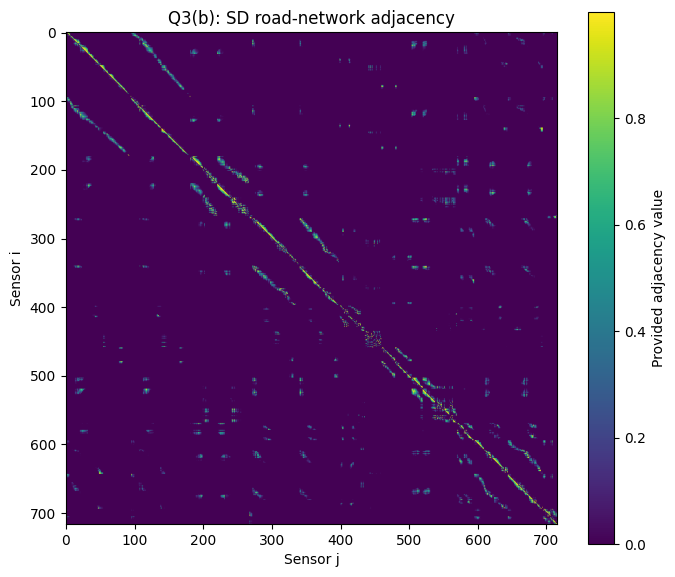

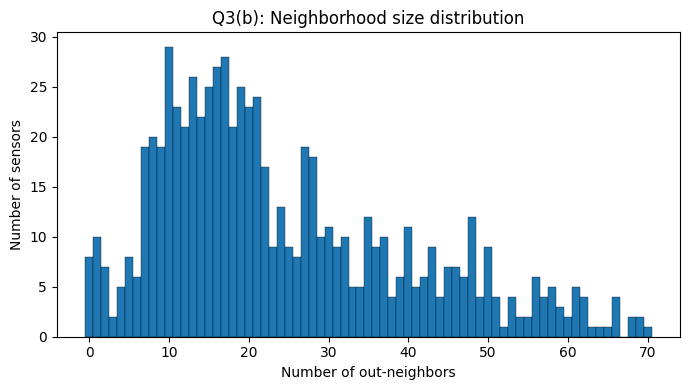

Selected sensor: 1123003 (index 307 )
1-hop count: 20 IDs: ['1108585', '1122487', '1113985', '1123002', '1108590', '1123029', '1123031', '1108592', '1120994', '1108489', '1122494', '1108429', '1123030', '1123006', '1108425', '1125201', '1125559', '1125527', '1125531', '1125546']
<=2-hop count: 38 IDs: ['1108415', '1115749', '1108717', '1108585', '1122487', '1113985', '1123002', '1108590', '1123029', '1123031', '1108592', '1120994', '1121001', '1108597', '1121037', '1108595', '1108491', '1115838', '1108450', '1108489', '1122494', '1108429', '1123030', '1123006', '1108425', '1108519', '1121034', '1121035', '1125201', '1125559', '1125527', '1125610', '1125531', '1126292', '1125219', '1125546', '1113760', '1125575']


In [7]:
binary = (A!=0)
edge_count = int(binary.sum())
deg_out = binary.sum(1)
deg_in = binary.sum(0)
is_symmetric = bool(np.allclose(A,A.T,rtol=1e-6,atol=1e-6))
bin_symmetric = bool(np.array_equal(binary,binary.T))
print('Nodes:',len(A),'Directed nonzero edges (no loops):',edge_count)
print('Weighted symmetric:',is_symmetric,'Unweighted topology symmetric:',bin_symmetric)
print('Out-degree min/mean/median/max:', int(deg_out.min()),float(deg_out.mean()),float(np.median(deg_out)),int(deg_out.max()))

fig,ax=plt.subplots(figsize=(7,6)); im=ax.imshow(A,cmap='viridis',aspect='equal')
fig.colorbar(im,ax=ax,label='Provided adjacency value');ax.set(xlabel='Sensor j',ylabel='Sensor i',title='Q3(b): SD road-network adjacency')
fig.tight_layout();fig.savefig(OUT/'q3_adjacency_heatmap.png',dpi=160);plt.show()
fig,ax=plt.subplots(figsize=(7,4)); ax.hist(deg_out,bins=np.arange(deg_out.max()+2)-.5,edgecolor='black',linewidth=.25)
ax.set(xlabel='Number of out-neighbors',ylabel='Number of sensors',title='Q3(b): Neighborhood size distribution')
fig.tight_layout();fig.savefig(OUT/'q3_degree_hist.png',dpi=160);plt.show()

selected_node = int(np.argsort(deg_out)[len(deg_out)//2])
one = set(np.flatnonzero(binary[selected_node]).tolist())
two = set(one)
for j in one: two.update(np.flatnonzero(binary[j]).tolist())
two.discard(selected_node)
print('Selected sensor:',sensor_ids[selected_node], '(index',selected_node,')')
print('1-hop count:',len(one),'IDs:',[sensor_ids[i] for i in sorted(one)])
print('<=2-hop count:',len(two),'IDs:',[sensor_ids[i] for i in sorted(two)])

In [8]:
raw_w = A[binary].astype(np.float64)
assert len(raw_w)>0 and np.all(raw_w>=0), 'Expected nonnegative graph weights/distances.'
if raw_w.max()>1.0+1e-6:
    scale=float(np.median(raw_w))
    affinity=np.zeros_like(A,dtype=np.float32)
    affinity[binary]=np.exp(-np.square(A[binary]/scale)).astype(np.float32)
    graph_interpretation='distance converted to Gaussian affinity; scale=median nonzero distance'
else:
    affinity=np.maximum(A,0).astype(np.float32)
    scale=None
    graph_interpretation='supplied weights used as nonnegative affinities'
W=affinity.copy()
np.fill_diagonal(W,1.)
fixed_dense = W / np.maximum(W.sum(axis=1,keepdims=True),1e-12)
assert np.allclose(fixed_dense.sum(1),1,atol=1e-5)
print('Fixed graph:',graph_interpretation, 'scale=',scale)
print('Row normalization; min/max row sum:',fixed_dense.sum(1).min(),fixed_dense.sum(1).max())
A_fixed = torch.tensor(fixed_dense,device=DEVICE,dtype=torch.float32)
with open(OUT/'data_graph_summary.json','w') as f:
    json.dump({'nodes':len(A),'edges_directed_excluding_diagonal':edge_count,
       'weighted_symmetric':is_symmetric,'topology_symmetric':bin_symmetric,
       'degree_min':int(deg_out.min()),'degree_mean':float(deg_out.mean()),
       'degree_max':int(deg_out.max()),'selected_sensor_id':sensor_ids[selected_node],
       'one_hop_ids':[sensor_ids[i] for i in sorted(one)],
       'two_hop_ids':[sensor_ids[i] for i in sorted(two)],
       'missing_fraction':nan_rates,'normalization_mean':global_mean,'normalization_std':global_std,
       'fixed_graph_policy':graph_interpretation,'fixed_graph_distance_scale':scale},f,indent=2)

Fixed graph: supplied weights used as nonnegative affinities scale= None
Row normalization; min/max row sum: 0.9999998 1.0000002


In [9]:
class TrafficWindows(Dataset):
    def __init__(self, values, observed, history=HISTORY, horizon=HORIZON, stride=1):
        assert len(values)==len(observed) and values.shape[1]==N_EXPECTED
        self.values=torch.from_numpy(values)
        self.observed=torch.from_numpy(observed)
        self.starts=np.arange(0,len(values)-history-horizon+1,stride,dtype=np.int32)
    def __len__(self): return len(self.starts)
    def __getitem__(self,i):
        s=int(self.starts[i]); h=HISTORY; f=HORIZON
        # (nodes,time) for Conv1d; target (nodes,horizon)
        x=self.values[s:s+h].T.contiguous()
        y=self.values[s+h:s+h+f].T.contiguous()
        m=self.observed[s+h:s+h+f].T.contiguous()
        return x,y,m

datasets = {k:TrafficWindows(*v,stride=(TRAIN_STRIDE if k=='train' else 1)) for k,v in splits.items()}
if DEV_FAST_RUN:
    from torch.utils.data import Subset
    datasets = {k:Subset(v,range(min(1024,len(v)))) for k,v in datasets.items()}
loaders={k:DataLoader(ds,batch_size=BATCH_SIZE,shuffle=(k=='train'),num_workers=NUM_WORKERS,
                   pin_memory=(DEVICE.type=='cuda'),drop_last=False) for k,ds in datasets.items()}
print('Samples by split:',{k:len(ds) for k,ds in datasets.items()})
xb,yb,mb=next(iter(loaders['train']))
print('X',tuple(xb.shape),'Y',tuple(yb.shape),'Observed mask',tuple(mb.shape))
assert xb.shape[1:]==(N_EXPECTED,HISTORY) and yb.shape[1:]==(N_EXPECTED,HORIZON)

Samples by split: {'train': 35125, 'validation': 8629, 'test': 26389}
X (64, 716, 8) Y (64, 716, 4) Observed mask (64, 716, 4)


In [10]:
class TemporalEncoder(nn.Module):
    def __init__(self, hidden=HIDDEN):
        super().__init__()
        self.conv=nn.Conv1d(1,hidden,kernel_size=3,padding=1)
        self.proj=nn.Linear(hidden*HISTORY,hidden)
    def forward(self,x):
        b,n,t=x.shape
        z=self.conv(x.reshape(b*n,1,t)).relu()
        z=self.proj(z.reshape(b*n,-1)).relu()
        return z.reshape(b,n,-1)

class STForecast(nn.Module):
    def __init__(self,kind='fixed'):
        super().__init__()
        assert kind in ('temporal','fixed','adaptive','hybrid')
        self.kind=kind
        self.temporal=TemporalEncoder()
        self.head=nn.Linear(HIDDEN,HORIZON) 
        if kind!='temporal': self.graph_weight=nn.Linear(HIDDEN,HIDDEN,bias=False)
        if kind in ('adaptive','hybrid'):
            self.E1 = nn.Parameter(torch.randn(N_EXPECTED, EMBED_DIM))
            self.E2 = nn.Parameter(torch.randn(N_EXPECTED, EMBED_DIM))
    def learned_adjacency(self):
        scores = torch.relu(self.E1 @ self.E2.T)
        k = 20
        indices = torch.topk(scores, k=k, dim=1).indices
        sparse_scores = torch.full_like(scores, float('-inf'))
        sparse_scores.scatter_(
            1, indices, scores.gather(1, indices)
        )
        return torch.softmax(sparse_scores, dim=1)
        
    def adjacency(self,fixed):
        if self.kind=='fixed': return fixed
        learned=self.learned_adjacency()
        if self.kind=='adaptive': return learned
        return 0.5*fixed+0.5*learned
    def forward(self,x,fixed):
        z=self.temporal(x)  # B,N,H
        if self.kind!='temporal':
            adj=self.adjacency(fixed)
            b,n,h=z.shape
            z2=z.permute(1,0,2).reshape(n,b*h)
            mixed=(adj@z2).reshape(n,b,h).permute(1,0,2)
            z = z + torch.relu(self.graph_weight(mixed))
        return self.head(z)  # B,N,4

@torch.no_grad()
def run_shape_checks():
    x=torch.randn(2,N_EXPECTED,HISTORY,device=DEVICE)
    for kind in ('temporal','fixed','adaptive','hybrid'):
        model=STForecast(kind).to(DEVICE)
        y=model(x,A_fixed)
        assert y.shape==(2,N_EXPECTED,HORIZON)
        if kind!='temporal': assert torch.allclose(model.adjacency(A_fixed).sum(1),torch.ones(N_EXPECTED,device=DEVICE),atol=2e-5)
        print(kind, 'params', sum(p.numel() for p in model.parameters()), 'output',tuple(y.shape))
run_shape_checks()

temporal params 4828 output (2, 716, 4)
fixed params 5404 output (2, 716, 4)
adaptive params 22588 output (2, 716, 4)
hybrid params 22588 output (2, 716, 4)


In [11]:
def masked_mae_torch(pred,y,mask):
    m=mask.float()
    return ((pred-y).abs()*m).sum()/m.sum().clamp_min(1.)

@torch.no_grad()
def evaluate(model,loader):
    model.eval()
    aerr=sqerr=cnt=0.
    step_abs=np.zeros(HORIZON,np.float64);step_sq=np.zeros(HORIZON,np.float64);step_cnt=np.zeros(HORIZON,np.float64)
    for x,y,mask in loader:
        x=x.to(DEVICE,non_blocking=True);y=y.to(DEVICE,non_blocking=True);mask=mask.to(DEVICE,non_blocking=True)
        diff=(model(x,A_fixed)-y)*global_std
        m=mask.float()
        aerr+=(diff.abs()*m).sum().item();sqerr+=((diff**2)*m).sum().item();cnt+=m.sum().item()
        step_abs+=(diff.abs()*m).sum(dim=(0,1)).cpu().numpy()
        step_sq+=((diff**2)*m).sum(dim=(0,1)).cpu().numpy()
        step_cnt+=m.sum(dim=(0,1)).cpu().numpy()
    assert cnt>0,'Evaluation split has no observed targets'
    return {'mae':aerr/cnt,'rmse':math.sqrt(sqerr/cnt),'observations':int(cnt),
            'horizon_mae':(step_abs/np.maximum(step_cnt,1)).tolist(),
            'horizon_rmse':np.sqrt(step_sq/np.maximum(step_cnt,1)).tolist()}

def train_one(kind):
    set_seed(SEED)
    model=STForecast(kind).to(DEVICE)
    if kind in ('adaptive', 'hybrid'):
        embedding_params = [model.E1, model.E2]
        other_params = [
            p for name, p in model.named_parameters()
            if name not in ('E1', 'E2')
        ]
    
        optim = torch.optim.Adam([
            {'params': other_params, 'weight_decay': WEIGHT_DECAY},
            {'params': embedding_params, 'weight_decay': 0.0}
        ], lr=LEARNING_RATE)
    else:
        optim = torch.optim.Adam(
            model.parameters(),
            lr=LEARNING_RATE,
            weight_decay=WEIGHT_DECAY
        )
    best=float('inf'); best_epoch=0; no_improve=0; history=[]
    t0=time.perf_counter()
    epochs=2 if DEV_FAST_RUN else MAX_EPOCHS
    for epoch in range(1,epochs+1):
        model.train();cum=0.;nvalid=0.
        for x,y,mask in loaders['train']:
            x=x.to(DEVICE,non_blocking=True);y=y.to(DEVICE,non_blocking=True);mask=mask.to(DEVICE,non_blocking=True)
            if not mask.any(): continue
            optim.zero_grad(set_to_none=True)
            pred=model(x,A_fixed)
            loss=masked_mae_torch(pred,y,mask)
            loss.backward()
            optim.step()
            nm=mask.sum().item(); cum+=loss.item()*nm;nvalid+=nm
        val=evaluate(model,loaders['validation'])
        history.append({'epoch':epoch,'train_mae_normalized':cum/max(nvalid,1),
                        'validation_mae':val['mae'],'validation_rmse':val['rmse']})
        print(f'{kind:9s} epoch {epoch:02d} | train normalized MAE={cum/max(nvalid,1):.4f} | val MAE={val["mae"]:.3f}, RMSE={val["rmse"]:.3f}')
        if val['mae']<best-1e-6:
            best=val['mae'];best_epoch=epoch;no_improve=0
            torch.save(model.state_dict(),OUT/f'{kind}_best.pt')
        else:
            no_improve+=1
            if no_improve>=PATIENCE:break
    if DEVICE.type=='cuda':torch.cuda.synchronize()
    elapsed=time.perf_counter()-t0
    model.load_state_dict(torch.load(OUT/f'{kind}_best.pt',map_location=DEVICE,weights_only=True))
    val=evaluate(model,loaders['validation'])
    tst=evaluate(model,loaders['test'])
    pd.DataFrame(history).to_csv(OUT/f'{kind}_training_history.csv',index=False)
    print(f'BEST {kind} epoch={best_epoch} | val MAE={val["mae"]:.3f} | test MAE={tst["mae"]:.3f} RMSE={tst["rmse"]:.3f} | training {elapsed:.1f}s')
    return model, {'model':kind,'adjacency':{'temporal':'None','fixed':'Fixed','adaptive':'Adaptive','hybrid':'Hybrid'}[kind],
                   'best_epoch':best_epoch,'training_seconds':elapsed,
                   'val_mae':val['mae'],'val_rmse':val['rmse'],'test_mae':tst['mae'],'test_rmse':tst['rmse'],
                   'val_by_horizon':val['horizon_mae'],'test_by_horizon':tst['horizon_mae'],
                   'test_rmse_by_horizon':tst['horizon_rmse']}

In [12]:
models={}; results=[]
for kind in ('temporal','fixed','adaptive','hybrid'):
    print('\n'+'='*62+'\nTraining '+kind+'\n'+'='*62)
    models[kind],row=train_one(kind)
    results.append(row)
    models[kind].cpu()
    if DEVICE.type=='cuda':torch.cuda.empty_cache()

results_df=pd.DataFrame(results)
print('\nQ6(a): all metrics in ORIGINAL flow units')
display(results_df[['model','adjacency','val_mae','val_rmse','test_mae','test_rmse','training_seconds','best_epoch']])
results_df.to_csv(OUT/'q6_results.csv',index=False)


Training temporal
temporal  epoch 01 | train normalized MAE=0.1608 | val MAE=61.770, RMSE=101.348
temporal  epoch 02 | train normalized MAE=0.1225 | val MAE=61.712, RMSE=99.280
temporal  epoch 03 | train normalized MAE=0.1212 | val MAE=60.121, RMSE=98.212
temporal  epoch 04 | train normalized MAE=0.1204 | val MAE=59.808, RMSE=98.167
temporal  epoch 05 | train normalized MAE=0.1199 | val MAE=59.475, RMSE=97.738
temporal  epoch 06 | train normalized MAE=0.1195 | val MAE=59.952, RMSE=97.957
temporal  epoch 07 | train normalized MAE=0.1192 | val MAE=59.177, RMSE=97.173
temporal  epoch 08 | train normalized MAE=0.1187 | val MAE=59.209, RMSE=97.296
temporal  epoch 09 | train normalized MAE=0.1187 | val MAE=59.159, RMSE=97.207
temporal  epoch 10 | train normalized MAE=0.1184 | val MAE=59.530, RMSE=97.569
temporal  epoch 11 | train normalized MAE=0.1186 | val MAE=58.917, RMSE=96.844
temporal  epoch 12 | train normalized MAE=0.1181 | val MAE=58.880, RMSE=96.746
temporal  epoch 13 | train norma

,model,adjacency,val_mae,val_rmse,test_mae,test_rmse,training_seconds,best_epoch
0,temporal,None,58.303167,95.606183,66.084047,104.938320,350.519708,23
1,fixed,Fixed,55.576383,91.641184,63.507955,101.054493,367.147818,24
2,adaptive,Adaptive,47.697962,80.126369,55.047607,87.189547,381.140497,25
3,hybrid,Hybrid,50.886295,84.908672,57.821370,91.908166,382.221680,25


Adaptive adjacency std: 0.015425155
Adaptive adjacency max: 0.92029405


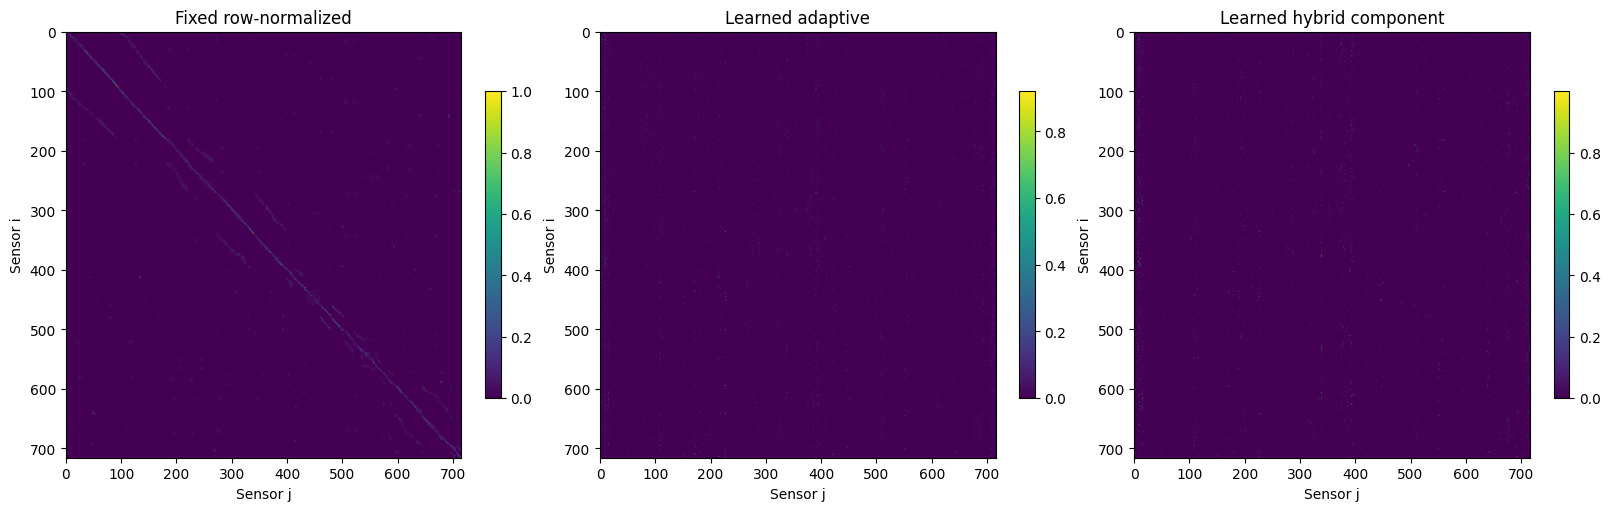

Top-10 overlap with physical graph: 255 of 7160 = 3.56%


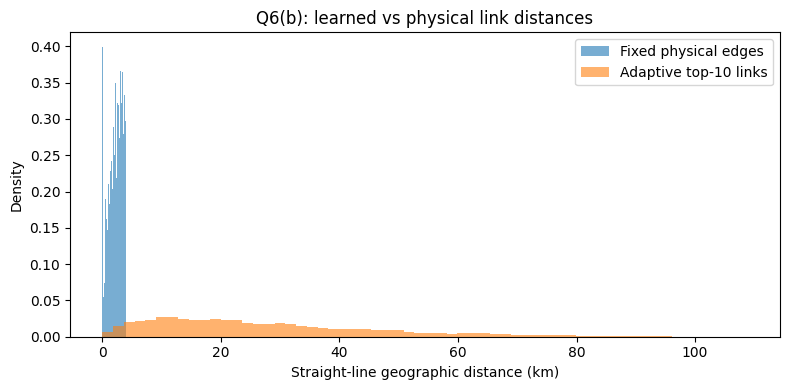

{'topk': 10, 'topk_physical_overlap': 255, 'topk_physical_overlap_fraction': 0.0356145251396648, 'topk_not_in_physical_fraction': 0.9643854748603352, 'physical_edge_median_km': 2.371061186383964, 'learned_topk_median_km': 23.084381314728134, 'learned_topk_within_4km_fraction': 0.04539106145251397}


In [13]:
@torch.no_grad()
def collect_adj(kind):
    model=models[kind].to(DEVICE).eval()
    if kind in ('adaptive','hybrid'):
        raw=model.learned_adjacency().cpu().numpy()
        used=model.adjacency(A_fixed).cpu().numpy()
        model.cpu();return raw,used
    model.cpu();return None,None
learned_adaptive,used_adaptive=collect_adj('adaptive')
print("Adaptive adjacency std:", learned_adaptive.std())
print("Adaptive adjacency max:", learned_adaptive.max())
assert learned_adaptive.std() > 1e-5, \
    "Learned adjacency is effectively uniform"
learned_hybrid,used_hybrid=collect_adj('hybrid')
np.save(OUT/'learned_adjacency_adaptive.npy',learned_adaptive)
np.save(OUT/'learned_adjacency_hybrid.npy',learned_hybrid)

fig,axes=plt.subplots(1,3,figsize=(16,5),constrained_layout=True)
for ax,mat,title in zip(axes,[fixed_dense,learned_adaptive,learned_hybrid],
                         ['Fixed row-normalized','Learned adaptive','Learned hybrid component']):
    im=ax.imshow(mat,aspect='auto',cmap='viridis');ax.set(title=title,xlabel='Sensor j',ylabel='Sensor i')
    fig.colorbar(im,ax=ax,shrink=.72)
fig.savefig(OUT/'q5_graph_comparison.png',dpi=160);plt.show()

K_NEIGHBORS=10
scores=learned_adaptive.copy();np.fill_diagonal(scores,-np.inf)
top_idx=np.argpartition(-scores,K_NEIGHBORS-1,axis=1)[:,:K_NEIGHBORS]
rows=np.arange(N_EXPECTED)[:,None]
overlap = binary[rows,top_idx]
num_overlap=int(overlap.sum())
prec_at_k=float(overlap.mean())
print(f'Top-{K_NEIGHBORS} overlap with physical graph:',num_overlap,'of',N_EXPECTED*K_NEIGHBORS,
      f'= {100*prec_at_k:.2f}%')

lat_col=next((x for x in ('Lat','lat','latitude') if x in meta.columns),None)
lon_col=next((x for x in ('Lng','lng','Lon','lon','longitude') if x in meta.columns),None)
geo_summary={}
if lat_col is not None and lon_col is not None:
    lat=np.radians(pd.to_numeric(meta[lat_col],errors='coerce').to_numpy(dtype=float))
    lon=np.radians(pd.to_numeric(meta[lon_col],errors='coerce').to_numpy(dtype=float))
    dlat=lat[:,None]-lat[None,:];dlon=lon[:,None]-lon[None,:]
    hav=np.sin(dlat/2)**2+np.cos(lat[:,None])*np.cos(lat[None,:])*np.sin(dlon/2)**2
    km=6371*2*np.arcsin(np.sqrt(np.clip(hav,0,1)))
    physical_d=km[binary]
    learned_d=km[rows,top_idx].ravel()
    physical_d=physical_d[np.isfinite(physical_d)]
    learned_d=learned_d[np.isfinite(learned_d)]
    if len(physical_d) and len(learned_d):
        geo_summary={'physical_edge_median_km':float(np.median(physical_d)),
                     'learned_topk_median_km':float(np.median(learned_d)),
                     'learned_topk_within_4km_fraction':float(np.mean(learned_d<=4))}
        fig,ax=plt.subplots(figsize=(8,4))
        ax.hist(physical_d,bins=60,alpha=.6,density=True,label='Fixed physical edges')
        ax.hist(learned_d,bins=60,alpha=.6,density=True,label='Adaptive top-10 links')
        ax.set(xlabel='Straight-line geographic distance (km)',ylabel='Density',
               title='Q6(b): learned vs physical link distances')
        ax.legend();fig.tight_layout();fig.savefig(OUT/'q6_learned_geography.png',dpi=160);plt.show()
else:
    print('Coordinates absent: geographical distance comparison not possible.')

graph_analysis={'topk':K_NEIGHBORS,'topk_physical_overlap':num_overlap,
                'topk_physical_overlap_fraction':prec_at_k,
                'topk_not_in_physical_fraction':1-prec_at_k,**geo_summary}
print(graph_analysis)
with open(OUT/'q6_graph_analysis.json','w') as f:json.dump(graph_analysis,f,indent=2)

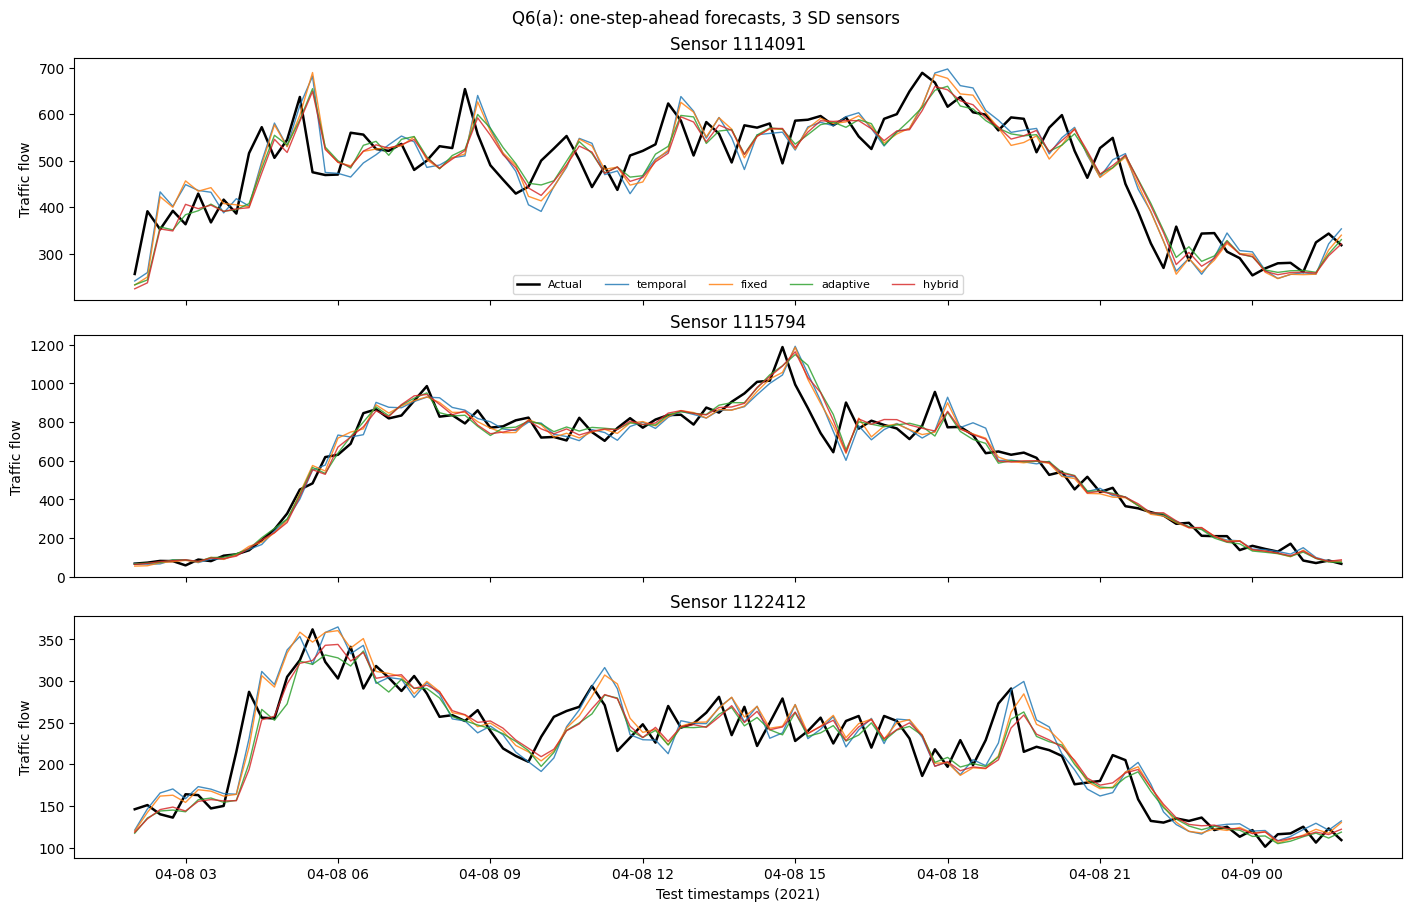

In [14]:
sample_ds=TrafficWindows(*splits['test'])
start_i=min(7*96,len(sample_ds)-100)
indices=list(range(start_i,start_i+96))
xs=torch.stack([sample_ds[i][0] for i in indices])
ys=torch.stack([sample_ds[i][1] for i in indices])
ms=torch.stack([sample_ds[i][2] for i in indices])
forecast_times=test_df.index[[i+HISTORY for i in indices]]

all_predictions={}
for kind,model in models.items():
    model.to(DEVICE).eval()
    out_batches=[]
    with torch.no_grad():
        for part in xs.split(BATCH_SIZE):
            out_batches.append(model(part.to(DEVICE),A_fixed).cpu().numpy())
    all_predictions[kind]=np.concatenate(out_batches,axis=0)*global_std+global_mean
    model.cpu()
actual=ys.numpy()*global_std+global_mean
observed=ms.numpy()

fig,axes=plt.subplots(3,1,figsize=(14,9),sharex=True,constrained_layout=True)
for ax,j in zip(axes,chosen):
    obs=np.where(observed[:,j,0],actual[:,j,0],np.nan)
    ax.plot(forecast_times,obs,color='black',lw=1.8,label='Actual')
    for kind,curve in all_predictions.items():
        ax.plot(forecast_times,curve[:,j,0],lw=1.,alpha=.83,label=kind)
    ax.set(ylabel='Traffic flow',title=f'Sensor {sensor_ids[j]}')
axes[0].legend(ncol=5,fontsize=8)
axes[-1].set_xlabel('Test timestamps (2021)')
fig.suptitle('Q6(a): one-step-ahead forecasts, 3 SD sensors')
fig.savefig(OUT/'q6_predicted_vs_actual_3_sensors.png',dpi=160);plt.show()

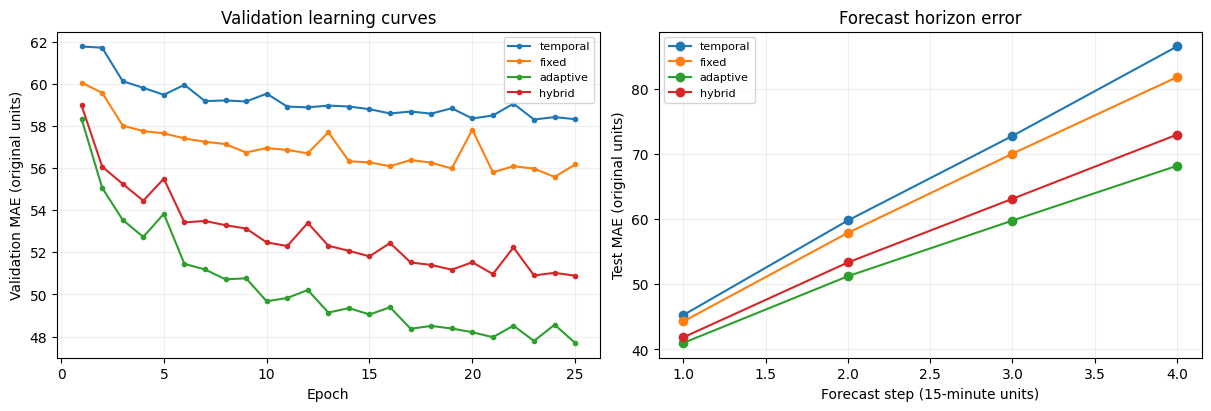

In [15]:
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for kind in models:
    hist=pd.read_csv(OUT/f'{kind}_training_history.csv')
    axes[0].plot(hist.epoch,hist.validation_mae,marker='o',ms=3,label=kind)
    row=next(r for r in results if r['model']==kind)
    axes[1].plot(range(1,HORIZON+1),row['test_by_horizon'],marker='o',label=kind)
axes[0].set(xlabel='Epoch',ylabel='Validation MAE (original units)',title='Validation learning curves')
axes[1].set(xlabel='Forecast step (15-minute units)',ylabel='Test MAE (original units)',title='Forecast horizon error')
for ax in axes:ax.grid(alpha=.2);ax.legend(fontsize=8)
fig.savefig(OUT/'q6_training_and_horizons.png',dpi=160);plt.show()

In [16]:
settings={'seed':SEED,'hidden':HIDDEN,'node_embedding_dim':EMBED_DIM,'batch_size':BATCH_SIZE,
          'max_epochs':MAX_EPOCHS,'patience':PATIENCE,'learning_rate':LEARNING_RATE,
          'weight_decay':WEIGHT_DECAY,'train_stride':TRAIN_STRIDE,'dev_fast_run':DEV_FAST_RUN,
          'graph_layer': 'residual: H = Z + ReLU(A Z Wg)',
          'history_steps':HISTORY,'forecast_horizon':HORIZON,'frequency':'15min',
          'splits':{'train':'2020-01-01 to 2020-12-31',
                    'validation':'2021-01-01 to 2021-03-31',
                    'test':'2021-04-01 to 2021-12-31'},
          'fixed_graph':graph_interpretation,'hybrid_alpha':0.5,
          'missing_targets':'excluded from train loss and evaluation; partial 15-min bins averaged',
          'missing_inputs':'imputed using training-only per-sensor mean',
          'normalization':'global train-only mean and std',
          'train_loss':'masked MAE on normalized targets',
          'selection':'best validation MAE (original units)',
          'python_version':platform.python_version(),'torch_version':torch.__version__,
          'numpy_version':np.__version__,'pandas_version':pd.__version__,
          'device':str(DEVICE),'gpu_name':torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
          'cpu':platform.processor(),'platform':platform.platform(),
          'input_paths':{'metadata':str(meta_path),'adjacency':str(adj_path),
                          '2020':str(locate_year(2020)),'2021':str(locate_year(2021))}}
with open(OUT/'run_configuration.json','w') as f:json.dump(settings,f,indent=2)
with open(OUT/'run_results.json','w') as f:json.dump(results,f,indent=2)
readme=OUT/'README_results.txt'
archive=OUT.parent/'AI651_PA3_Q3_Q7_results.zip'
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob('*'):
        if p.is_file():z.write(p,p.relative_to(OUT.parent))
print('Output folder:',OUT)
print('Results ZIP:',archive)
print('Saved files:')
for p in sorted(OUT.iterdir()):print(' ',p.name,round(p.stat().st_size/1e6,2),'MB')

Output folder: /kaggle/working/pa3_results
Results ZIP: /kaggle/working/AI651_PA3_Q3_Q7_results.zip
Saved files:
  adaptive_best.pt 0.09 MB
  adaptive_training_history.csv 0.0 MB
  data_graph_summary.json 0.0 MB
  fixed_best.pt 0.03 MB
  fixed_training_history.csv 0.0 MB
  hybrid_best.pt 0.09 MB
  hybrid_training_history.csv 0.0 MB
  learned_adjacency_adaptive.npy 2.05 MB
  learned_adjacency_hybrid.npy 2.05 MB
  q3_adjacency_heatmap.png 0.16 MB
  q3_degree_hist.png 0.03 MB
  q3_week_3_sensors.png 0.3 MB
  q5_graph_comparison.png 0.3 MB
  q6_graph_analysis.json 0.0 MB
  q6_learned_geography.png 0.05 MB
  q6_predicted_vs_actual_3_sensors.png 0.52 MB
  q6_results.csv 0.0 MB
  q6_training_and_horizons.png 0.18 MB
  run_configuration.json 0.0 MB
  run_results.json 0.0 MB
  sd_adjacency_raw.npy 2.05 MB
  sensor_ids.npy 0.02 MB
  temporal_best.pt 0.02 MB
  temporal_training_history.csv 0.0 MB
